# Implementing Gaussian Mixture Models

## Import the library

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

from scipy.cluster.hierarchy import (
    linkage,
    dendrogram
)

## Load the dataset

In [2]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)

X = iris.data
y = iris.target

print(X.head())
print("Dataset shape:", X.shape)
print(X.describe())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
Dataset shape: (150, 4)
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   


## Visualize the Data
```
What does this do?
- plt.subplots() creates a plotting area.
- ax.scatter() creates a scatter plot.
- The first argument represents the X-axis.
- The second argument represents the Y-axis.
- set_xlabel() and set_ylabel() label the axes.
- set_title() gives the graph a title.
- plt.show() displays the graph.
```

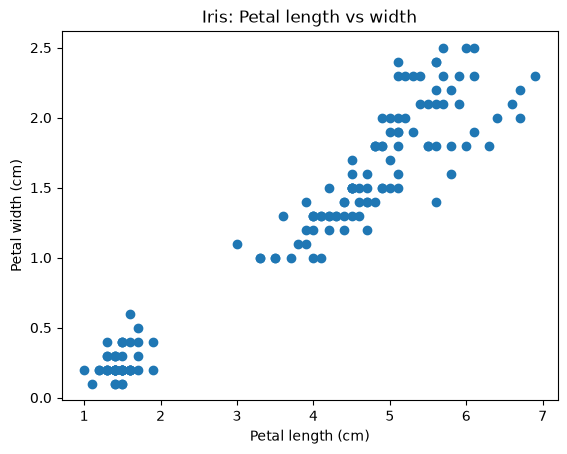

In [3]:
fig, ax = plt.subplots()

ax.scatter(
    X["petal length (cm)"],
    X["petal width (cm)"]
)

ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Petal width (cm)")
ax.set_title("Iris: Petal length vs width")

plt.show()

##### Sepal Length against Sepal Width:

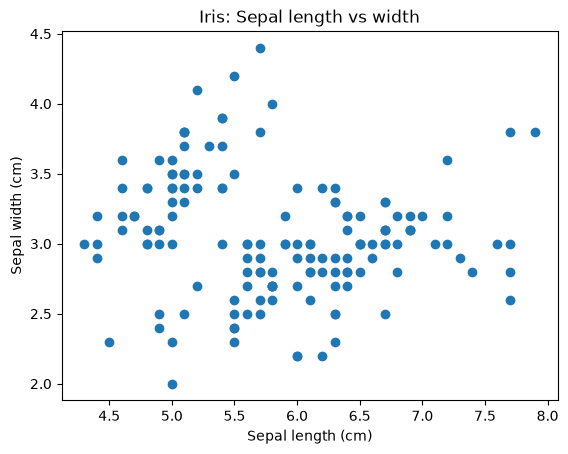

In [5]:
fig, ax = plt.subplots()

ax.scatter(
    X["sepal length (cm)"],
    X["sepal width (cm)"]
)

ax.set_xlabel("Sepal length (cm)")
ax.set_ylabel("Sepal width (cm)")
ax.set_title("Iris: Sepal length vs width")

plt.show()

## Standardize the Features

This is a very important preprocessing step.

Different features may have different scales. Features with larger numerical values or variation can disproportionately influence distance calculations.

Standardization converts features to a comparable scale.

The formula is:
$$
z=\frac{x-\mu}{\sigma}
$$

Where:
- $(x)$ = Original value.
- $(\mu)$ = Mean.
- $(\sigma)$ = Standard deviation.
- $(z)$ = Standardized value.

After standardization, each feature has approximately:
- Mean = 0.
- Standard deviation = 1.

In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original data:")
print(X.iloc[:2].values)

print("\nStandardized data:")
print(X_scaled[:2])

Original data:
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]]

Standardized data:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]]


## Determine the number of components
The notebook uses the Bayesian Information Criterion (BIC).

BIC helps compare models by balancing goodness of fit against model complexity.

Lower BIC is better when comparing candidate models fitted to the same data.

**Understanding the parameters:**
| Parameter | Explanation |
|---|---|
| `n_components` | Number of Gaussian distributions |
| `covariance_type="full"` | Each component has its own unrestricted covariance matrix |
| `random_state=42` | Makes initialization reproducible |
| `fit()` | Estimates the model parameters |
| `bic()` | Calculates the Bayesian Information Criterion |

In [7]:
components = range(1, 9)

bics = []

for c in components:

    gmm = GaussianMixture(
        n_components=c,
        covariance_type="full",
        random_state=42
    )

    gmm.fit(X_scaled)

    bics.append(gmm.bic(X_scaled))

## Visualize BIC

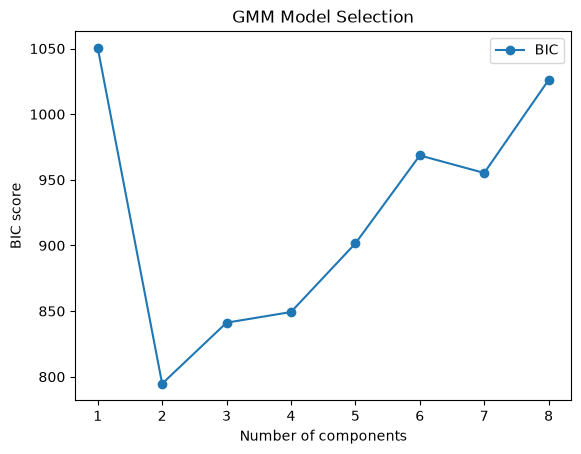

In [8]:
plt.plot(
    list(components),
    bics,
    marker="o",
    label="BIC"
)

plt.xlabel("Number of components")
plt.ylabel("BIC score")
plt.title("GMM Model Selection")

plt.legend()
plt.show()

How to interpret the graph:
- Identify the component count with the lowest BIC.
- This is the preferred candidate among the models tested.
- Do not automatically assume that three components are always optimal.

## Fit the GMM model

In [9]:
best_c = 3

gmm = GaussianMixture(
    n_components=best_c,
    covariance_type="full",
    random_state=0
)

gmm_labels = gmm.fit_predict(X_scaled)

print(gmm_labels[:10])

[1 1 1 1 1 1 1 1 1 1]


The model:
1. Creates three Gaussian distributions.
2. Estimates their parameters.
3. Calculates the membership probabilities.
4. Assigns each observation to its most likely cluster.

## Obtain membership probabilities
This is an important feature of GMM.

In [10]:
probabilities = gmm.predict_proba(X_scaled)

print(probabilities[:5])

[[6.68458864e-44 1.00000000e+00 7.44269825e-35]
 [6.88281903e-31 1.00000000e+00 2.97316198e-28]
 [7.26674155e-36 1.00000000e+00 4.82530460e-30]
 [1.16681891e-31 1.00000000e+00 3.06088222e-26]
 [2.43353714e-46 1.00000000e+00 3.11573125e-35]]


## Visualize the GMM clusters

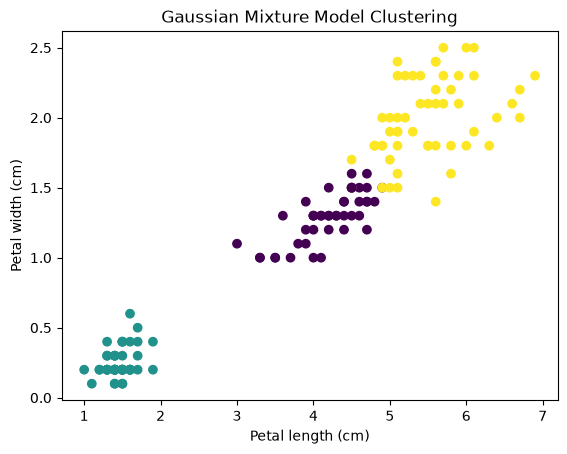

In [11]:
fig, ax = plt.subplots()

ax.scatter(
    X["petal length (cm)"],
    X["petal width (cm)"],
    c=gmm_labels
)

ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Petal width (cm)")
ax.set_title("Gaussian Mixture Model Clustering")

plt.show()